### Make temporary directory

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_OUMDUOEZIXAQ


### Main

In [3]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [4]:
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import os
from nd2reader import ND2Reader
from microfilm.microplot import microshow
from skimage import exposure, filters, transform
from skimage import io
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

In [5]:
sl = 119820

tmp = []
for i in range(4):
    tmp.append(io.imread(f"/bucket/ReiterU/DBS/data/20231018_F24_squid_33dph_TO_PRO_3_alpha_tubulin/stitched_692BP/RES(10609x9316x1336)/624550_266910_{sl+25*i}.tif"))
img1 = np.array(tmp).max(axis=0)

tmp = []
for i in range(4):
    tmp.append(io.imread(f"/bucket/ReiterU/DBS/data/20231018_F24_squid_33dph_TO_PRO_3_alpha_tubulin/stitched_624BP/RES(10609x9316x1336)/624550_266910_{sl+25*i}.tif"))
img2 = np.array(tmp).max(axis=0)

raw = np.stack((img1, img2))
print(raw.shape)

(2, 10609, 9316)


### Crop and rotate

In [6]:
cropped = raw[:, 800:9000, 2250:8800]

In [7]:
raw2 = []
for i in range(2):
    raw2.append(transform.rotate(cropped[i], -105, resize=True, preserve_range=True))
raw2 = np.array(raw2)
raw2 = raw2[:, 1300:7200, 200:-200]

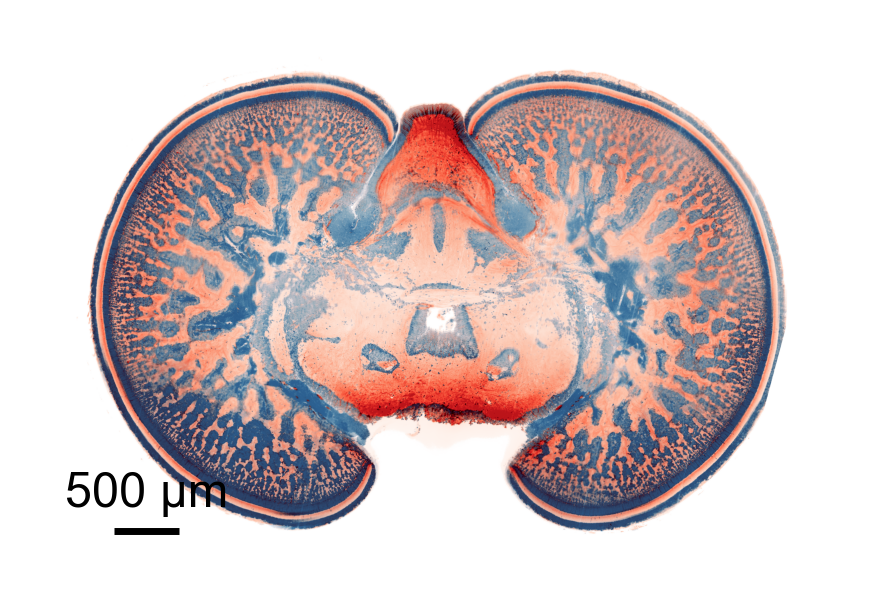

In [8]:
gamma = 1.5
vmax1, vmin1 = 4000, 500
vmax2, vmin2 = 25000, 500
img = np.power(raw2[:, ::1, ::1], 1/gamma)
nuclear_norm = np.clip((img[0] - np.power(vmin1, 1/gamma)) / (np.power(vmax1, 1/gamma) - np.power(vmin1, 1/gamma)), 0, 1)
tubulin_norm = np.clip((img[1] - np.power(vmin2, 1/gamma)) / (np.power(vmax2, 1/gamma) - np.power(vmin2, 1/gamma)), 0, 1)

cm1 = plt.get_cmap('Blues')
colors = cm1(np.linspace(0, 0.7, 256))
colors[0] = (1,1,1,1)
interted_cm1 = ListedColormap(1 - colors[:, :3])

cm2 = plt.get_cmap('Reds')
colors = cm2(np.linspace(0.0, 0.8, 256))
colors[0] = (1,1,1,1)
inverted_cm2 = ListedColormap(1 - colors[:, :3])

nuclear_rgb = interted_cm1(nuclear_norm)[..., :3]
tubulin_rgb = inverted_cm2(tubulin_norm)[..., :3]

overlay = nuclear_rgb + tubulin_rgb
overlay = np.clip(overlay, 0, 1)
inverted = 1 - overlay

# Show
fig, ax = plt.subplots(figsize=(2,2), dpi=500)
ax.imshow(inverted)
ax.axis('off')

# scalebar
real_length_um = 500
pixel_size_um = 0.65
scalebar = AnchoredSizeBar(ax.transData,
                           real_length_um / pixel_size_um,
                           f'{real_length_um} µm',
                           'lower left', pad=0.2, color='black',
                            frameon=False, label_top=True, size_vertical=10)
ax.add_artist(scalebar)
plt.savefig(os.path.join(tmpdir, "OL_coronal_blue_red.pdf"), bbox_inches='tight', transparent=True)
plt.show()

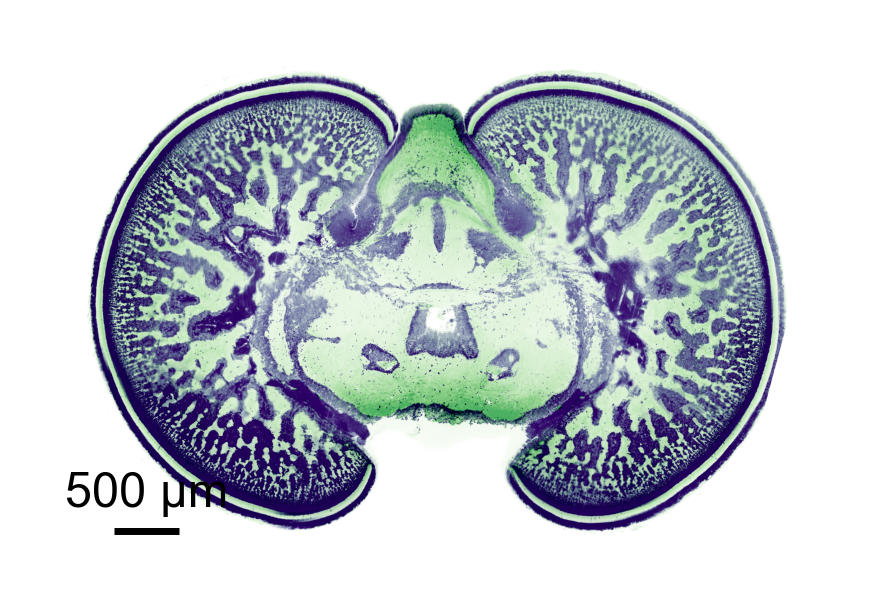

In [9]:
gamma = 1.5
vmax1, vmin1 = 4000, 500
vmax2, vmin2 = 25000, 500
img = np.power(raw2[:, ::1, ::1], 1/gamma)
nuclear_norm = np.clip((img[0] - np.power(vmin1, 1/gamma)) / (np.power(vmax1, 1/gamma) - np.power(vmin1, 1/gamma)), 0, 1)
tubulin_norm = np.clip((img[1] - np.power(vmin2, 1/gamma)) / (np.power(vmax2, 1/gamma) - np.power(vmin2, 1/gamma)), 0, 1)

cm1 = plt.get_cmap('Purples')
colors = cm1(np.linspace(0, 1, 256))
colors[0] = (1,1,1,1)
interted_cm1 = ListedColormap(1 - colors[:, :3])

cm2 = plt.get_cmap('Greens')
colors = cm2(np.linspace(0.0, 0.6, 256))
colors[0] = (1,1,1,1)
inverted_cm2 = ListedColormap(1 - colors[:, :3])

nuclear_rgb = interted_cm1(nuclear_norm)[..., :3]
tubulin_rgb = inverted_cm2(tubulin_norm)[..., :3]

overlay = nuclear_rgb + tubulin_rgb
overlay = np.clip(overlay, 0, 1)
inverted = 1 - overlay

# Show
fig, ax = plt.subplots(figsize=(2,2), dpi=500)
ax.imshow(inverted)
ax.axis('off')

# scalebar
real_length_um = 500
pixel_size_um = 0.65
scalebar = AnchoredSizeBar(ax.transData,
                           real_length_um / pixel_size_um,
                           f'{real_length_um} µm',
                           'lower left', pad=0.2, color='black',
                            frameon=False, label_top=True, size_vertical=10)
ax.add_artist(scalebar)
plt.savefig(os.path.join(tmpdir, "OL_coronal_blue_red.pdf"), bbox_inches='tight', transparent=True)
plt.show()

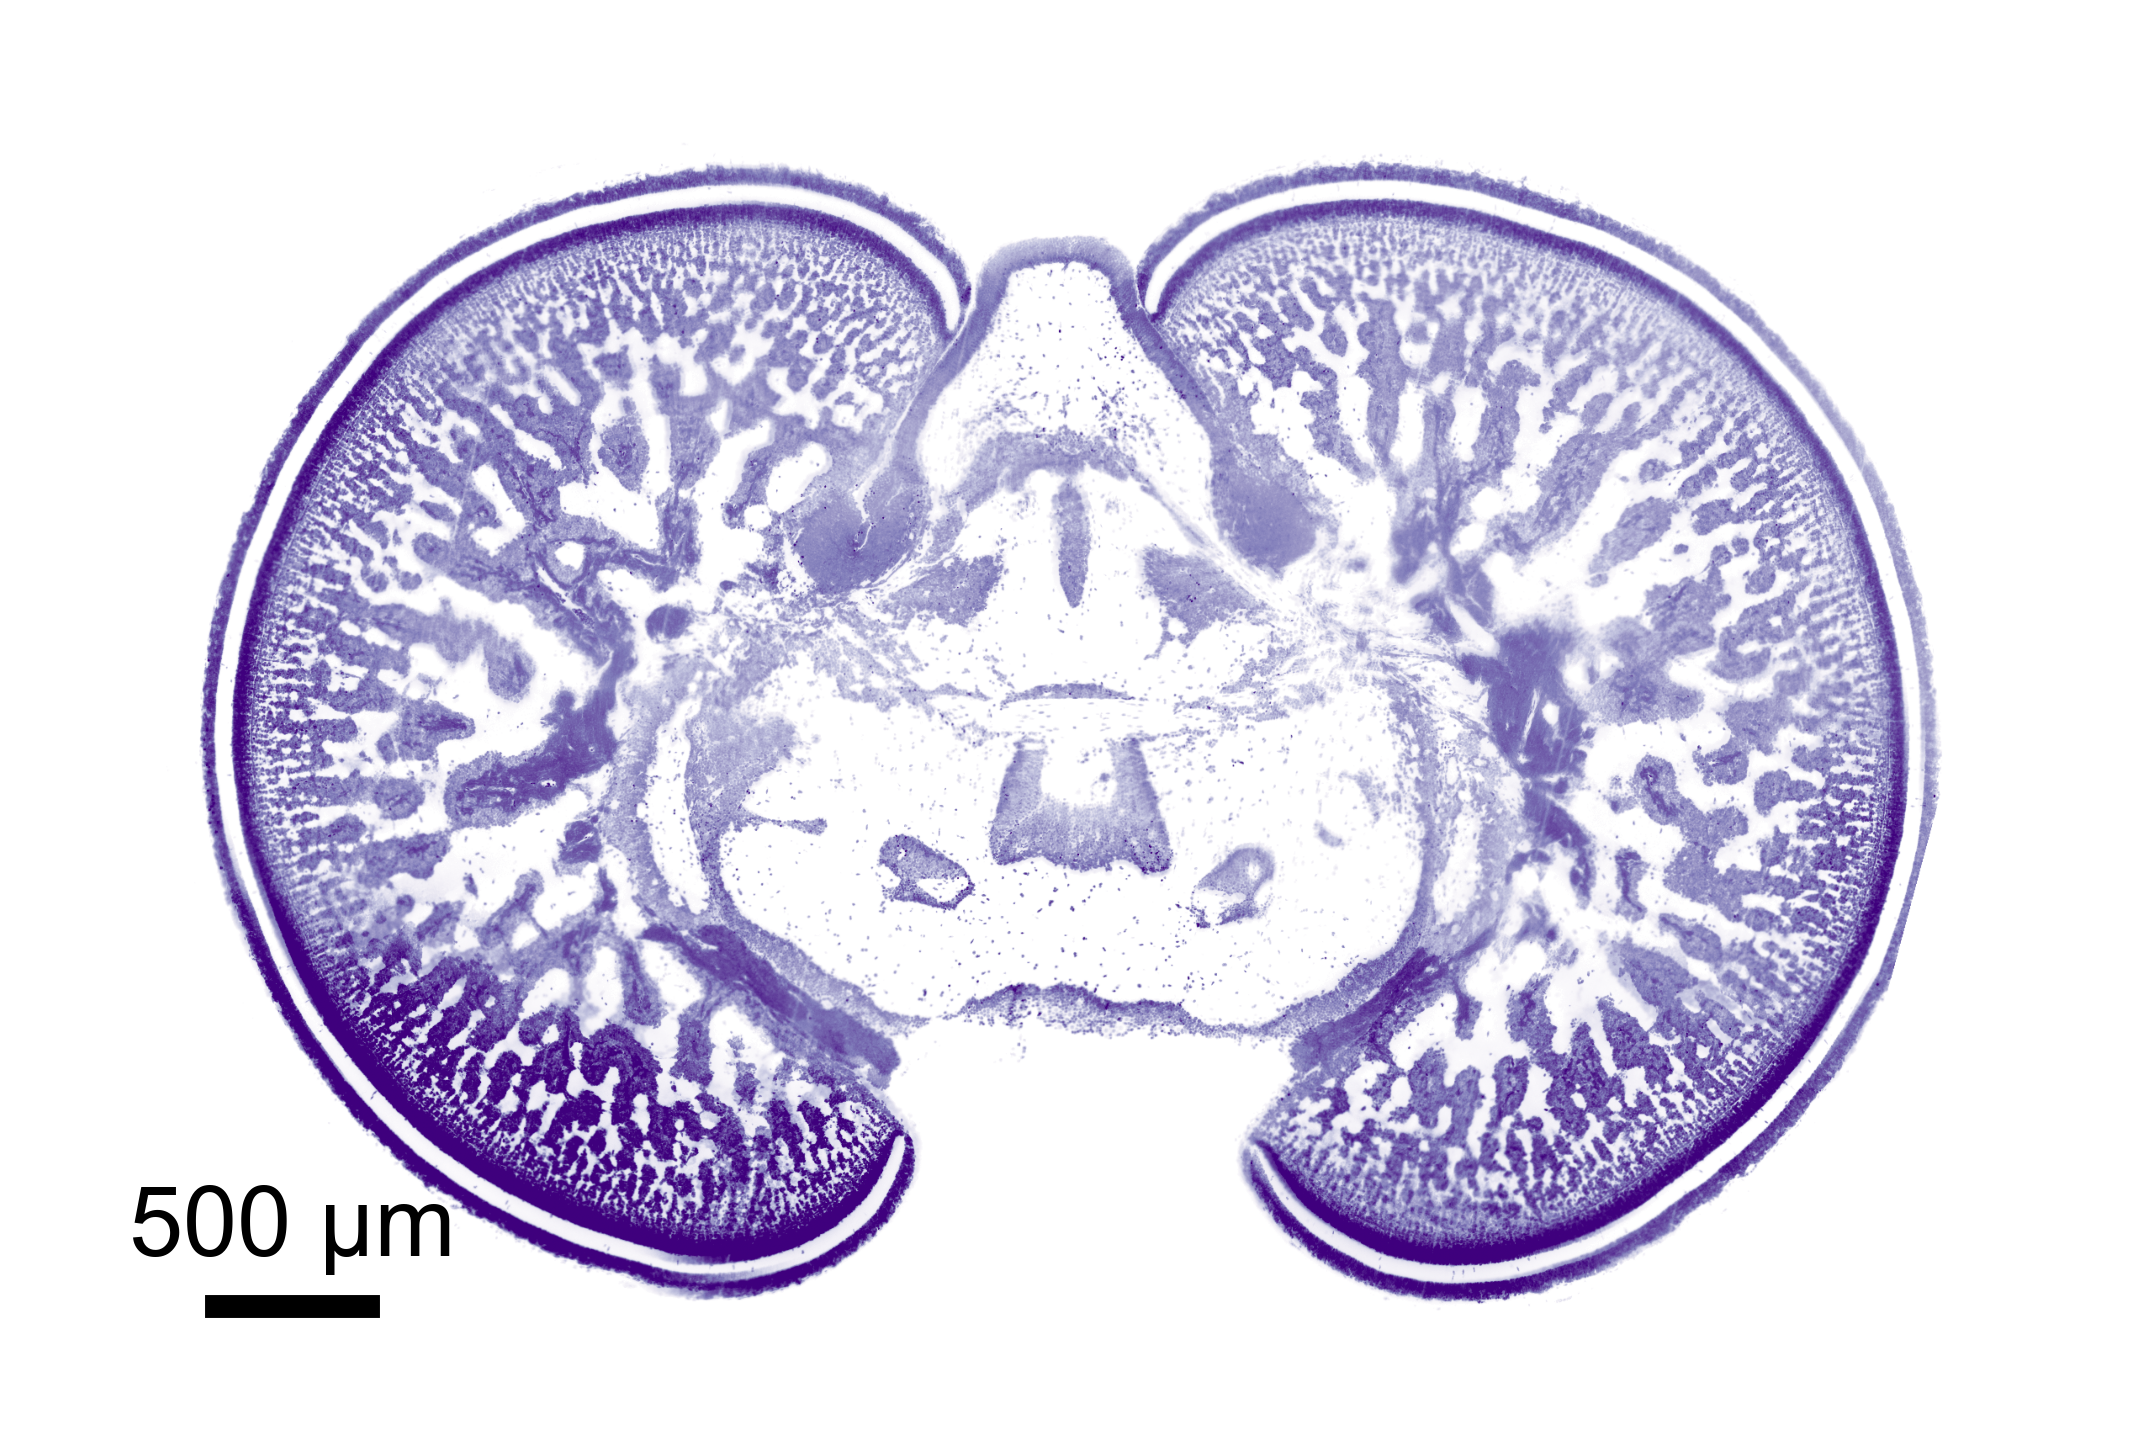

In [10]:
gamma = 2.0
vmax1, vmin1 = 6000, 400
vmax2, vmin2 = 25000, 150
img = np.power(raw2[:, ::4, ::4], 1/gamma)
nuclear_norm = np.clip((img[0] - np.power(vmin1, 1/gamma)) / (np.power(vmax1, 1/gamma) - np.power(vmin1, 1/gamma)), 0, 1)
tubulin_norm = np.clip((img[1] - np.power(vmin2, 1/gamma)) / (np.power(vmax2, 1/gamma) - np.power(vmin2, 1/gamma)), 0, 1)

purples = plt.get_cmap('Purples')
colors = purples(np.linspace(0, 1, 256))
colors[0] = (1,1,1,1)
inverted_purple = ListedColormap(1 - colors[:, :3])

reds = plt.get_cmap('Purples')
colors = reds(np.linspace(0.0, 1.0, 256))
colors[0] = (1,1,1,1)
inverted_reds = ListedColormap(1 - colors[:, :3])

nuclear_rgb = inverted_purple(nuclear_norm)[..., :3]
tubulin_rgb = inverted_reds(tubulin_norm)[..., :3]

overlay = nuclear_rgb
# overlay = tubulin_rgb
overlay = np.clip(overlay, 0, 1)
inverted = 1 - overlay

# Show
fig, ax = plt.subplots(figsize=(2.5,2.5), dpi=1000)
ax.imshow(inverted)
ax.axis('off')

# scalebar
real_length_um = 500
pixel_size_um = 0.65 * 4
scalebar = AnchoredSizeBar(ax.transData,
                           real_length_um / pixel_size_um,
                           f'{real_length_um} µm',
                           'lower left', pad=0.2, color='black',
                            frameon=False, label_top=True, size_vertical=10)
ax.add_artist(scalebar)
plt.savefig(os.path.join(tmpdir, "OL_coronal_purple.pdf"), bbox_inches='tight', transparent=True)
plt.show()

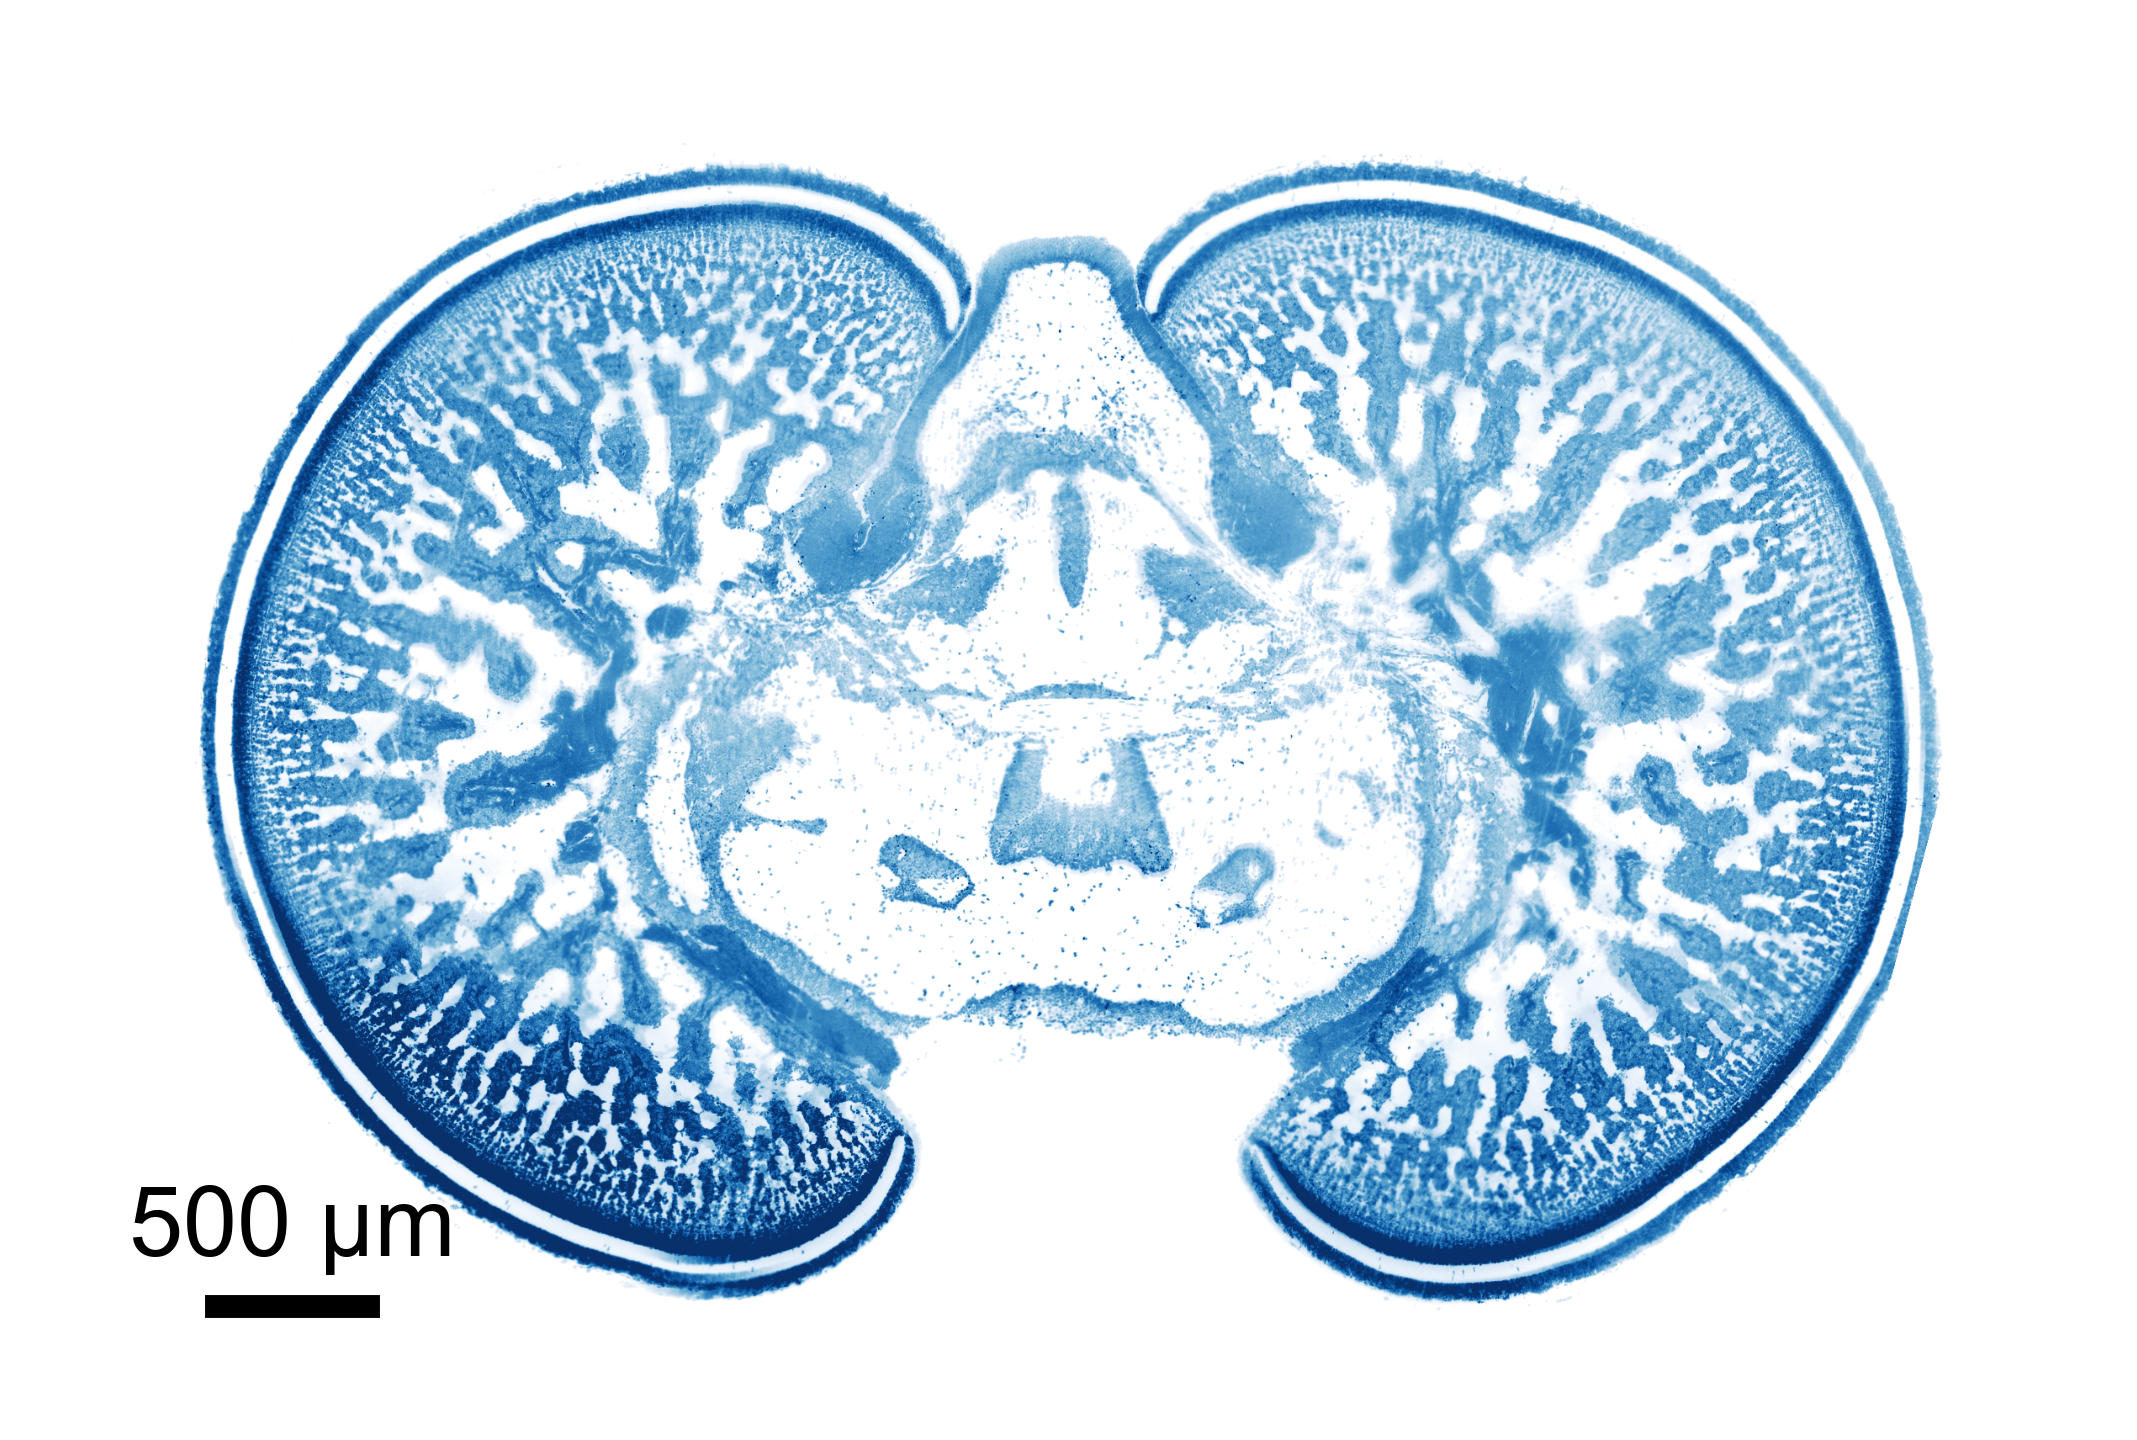

In [11]:
gamma = 2.0
vmax1, vmin1 = 6000, 400
vmax2, vmin2 = 25000, 150
img = np.power(raw2[:, ::4, ::4], 1/gamma)
nuclear_norm = np.clip((img[0] - np.power(vmin1, 1/gamma)) / (np.power(vmax1, 1/gamma) - np.power(vmin1, 1/gamma)), 0, 1)
tubulin_norm = np.clip((img[1] - np.power(vmin2, 1/gamma)) / (np.power(vmax2, 1/gamma) - np.power(vmin2, 1/gamma)), 0, 1)

purples = plt.get_cmap('Blues')
colors = purples(np.linspace(0, 1, 256))
colors[0] = (1,1,1,1)
inverted_purple = ListedColormap(1 - colors[:, :3])

reds = plt.get_cmap('Purples')
colors = reds(np.linspace(0.0, 1.0, 256))
colors[0] = (1,1,1,1)
inverted_reds = ListedColormap(1 - colors[:, :3])

nuclear_rgb = inverted_purple(nuclear_norm)[..., :3]
tubulin_rgb = inverted_reds(tubulin_norm)[..., :3]

overlay = nuclear_rgb
# overlay = tubulin_rgb
overlay = np.clip(overlay, 0, 1)
inverted = 1 - overlay

# Show
fig, ax = plt.subplots(figsize=(2.5,2.5), dpi=1000)
ax.imshow(inverted)
ax.axis('off')

# scalebar
real_length_um = 500
pixel_size_um = 0.65 * 4
scalebar = AnchoredSizeBar(ax.transData,
                           real_length_um / pixel_size_um,
                           f'{real_length_um} µm',
                           'lower left', pad=0.2, color='black',
                            frameon=False, label_top=True, size_vertical=10)
ax.add_artist(scalebar)
plt.savefig(os.path.join(tmpdir, "OL_coronal_blues.pdf"), bbox_inches='tight', transparent=True)
plt.show()

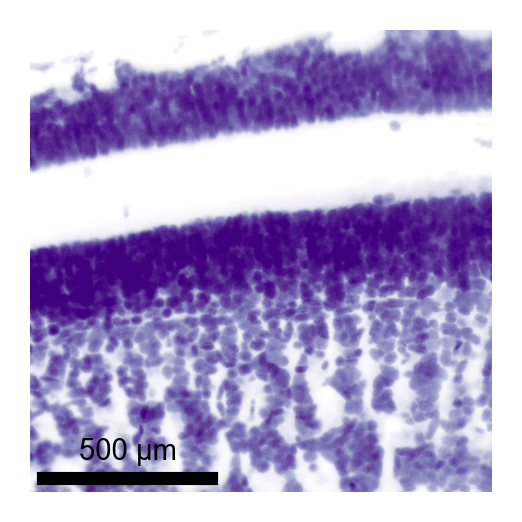

In [19]:
# gamma = 2.0
# vmax1, vmin1 = 5000, 500
# vmax2, vmin2 = 25000, 150
# img = np.power(raw2[:, 320:820:1, 2500:3000:1], 1/gamma)
# nuclear_norm = np.clip((img[0] - np.power(vmin1, 1/gamma)) / (np.power(vmax1, 1/gamma) - np.power(vmin1, 1/gamma)), 0, 1)
# tubulin_norm = np.clip((img[1] - np.power(vmin2, 1/gamma)) / (np.power(vmax2, 1/gamma) - np.power(vmin2, 1/gamma)), 0, 1)

# purples = plt.get_cmap('Purples')
# colors = purples(np.linspace(0, 1, 256))
# colors[0] = (1,1,1,1)
# inverted_purple = ListedColormap(1 - colors[:, :3])

# reds = plt.get_cmap('Purples')
# colors = reds(np.linspace(0.0, 1.0, 256))
# colors[0] = (1,1,1,1)
# inverted_reds = ListedColormap(1 - colors[:, :3])

# nuclear_rgb = inverted_purple(nuclear_norm)[..., :3]
# tubulin_rgb = inverted_reds(tubulin_norm)[..., :3]

# overlay = nuclear_rgb
# # overlay = tubulin_rgb
# overlay = np.clip(overlay, 0, 1)
# inverted = 1 - overlay

# # Show
# fig, ax = plt.subplots(figsize=(2,2), dpi=300)
# ax.imshow(inverted)
# ax.axis('off')

# # scalebar
# real_length_um = 500
# pixel_size_um = 0.65 * 4
# scalebar = AnchoredSizeBar(ax.transData,
#                            real_length_um / pixel_size_um,
#                            f'{real_length_um} µm',
#                            'lower left', pad=0.2, color='black',
#                             frameon=False, label_top=True, size_vertical=10)
# ax.add_artist(scalebar)
# plt.savefig("OL_coronal.pdf", bbox_inches='tight', transparent=True)
# plt.show()

### Copy data to bucket

In [12]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250428_brain_anatomy_figure"
print(f"cp -f {tmpdir}/* {savedir}")

cp -f /flash/ReiterU/tmp/tomo_OUMDUOEZIXAQ/* /bucket/ReiterU/OLdev/analysis/20250428_brain_anatomy_figure
